# Nivel 3: transferencia hacia documentos industriales

PURE nunca se usa para entrenar, solo para evaluar. Tres condiciones, todas sin particiones porque el conjunto de prueba es ajeno al de entrenamiento:

1. Unión: entrena con A+B completo (973 requisitos) y predice los 958 de PURE.
2. Solo A: entrena con A (625 requisitos).
3. Solo B: entrena con B (348 requisitos).

La evaluación usa el estándar PURE-300: la cifra principal es sobre los 265 requisitos confirmados y los 300 completos se reportan aparte. Las métricas de este cuaderno se calculan sobre todas las predicciones; la Tabla 3 del artículo usa la media por documento y la genera `code/tablas.py`. Las predicciones de BERT las produce `nivel3_bert.py`; aquí solo se leen.

In [1]:
import os
import re
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             cohen_kappa_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_score, recall_score)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from tabulate import tabulate

SPLIT_SEED = 42
DATOS = os.path.join("..", "..", "datasets")
CSV_CORPUS = os.path.join(DATOS, "harmonized", "corpus_all.csv")
CSV_GOLD = os.path.join(DATOS, "anotacion", "gold_pure300.csv")
DIR_NIVEL3 = os.path.join(DATOS, "nivel3")
DIR_FIGURAS = os.path.join(DIR_NIVEL3, "figuras")
os.makedirs(DIR_FIGURAS, exist_ok=True)
SUBDIR = {"union": "transferencia-union", "soloA": "transferencia-soloA",
          "soloB": "transferencia-soloB"}
CONDICIONES = ("union", "soloA", "soloB")
CLAVE_ENTREN = {"union": "AB", "soloA": "A", "soloB": "B"}
ETIQUETA_COND = {"union": "A+B", "soloA": "solo A", "soloB": "solo B"}

CLASES = ["F", "NFR"]
MODELOS_CLASICOS = ["TF-IDF + MNB", "TF-IDF + LinearSVC", "fastText + LogReg"]
MODELOS = MODELOS_CLASICOS + ["BERT (NoRBERT)"]

todo = pd.read_csv(CSV_CORPUS, dtype=str)
entren = {}
for letra, nombre in (("A", "PROMISE"), ("B", "PROMISE_exp_new")):
    d = todo[todo.corpus == nombre]
    entren[letra] = {"X": d.text.values, "y": d.label_binary.values}
entren["AB"] = {k: np.concatenate([entren["A"][k], entren["B"][k]])
                for k in ("X", "y")}
pure = todo[todo.corpus == "PURE"].reset_index(drop=True)
gold = pd.read_csv(CSV_GOLD, dtype=str)

print(tabulate([["entrenamiento union (A+B)", len(entren["AB"]["y"])],
                ["entrenamiento solo A", len(entren["A"]["y"])],
                ["entrenamiento solo B", len(entren["B"]["y"])],
                ["PURE (prueba, nunca entrena)", len(pure)],
                ["estandar PURE-300", len(gold)],
                ["  de los cuales son requisitos confirmados",
                 int((gold.es_requisito == "si").sum())]],
               headers=["conjunto", "requisitos"], tablefmt="github"))

| conjunto                                 |   requisitos |
|------------------------------------------|--------------|
| entrenamiento union (A+B)                |          973 |
| entrenamiento solo A                     |          625 |
| entrenamiento solo B                     |          348 |
| PURE (prueba, nunca entrena)             |          958 |
| estandar PURE-300                        |          300 |
| de los cuales son requisitos confirmados |          265 |


## 1. Predicciones de los clásicos

Cada condición entrena una vez por modelo con su corpus completo y predice los 958 requisitos de PURE. Se guardan con la etiqueta del estándar cuando el requisito pertenece a él.

In [2]:
TFIDF_CONF = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
_ft = {}

def vectores_fasttext(clave, textos):
    if "modelo" not in _ft:
        import gensim.downloader as api
        _ft["modelo"] = api.load("fasttext-wiki-news-subwords-300")
    ft = _ft["modelo"]
    if clave not in _ft:
        V = np.zeros((len(textos), ft.vector_size))
        for i, t in enumerate(textos):
            tokens = [w for w in re.findall(r"[a-zA-Z]+", t.lower())
                      if w in ft.key_to_index]
            if tokens:
                V[i] = np.mean([ft[w] for w in tokens], axis=0)
        _ft[clave] = V
    return _ft[clave]

def constructor(nombre):
    if nombre == "TF-IDF + MNB":
        return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_CONF)),
                         ("clf", MultinomialNB())])
    if nombre == "TF-IDF + LinearSVC":
        return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_CONF)),
                         ("clf", LinearSVC(C=1.0))])
    return Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=2000,
                                               random_state=SPLIT_SEED))])

def ruta_cond(cond, quien):
    return os.path.join(DIR_NIVEL3, SUBDIR[cond],
                        f"nivel3_{cond}_predicciones_{quien}.csv")

gold_por_id = dict(zip(gold.req_id, gold.etiqueta))
esreq_por_id = dict(zip(gold.req_id, gold.es_requisito))

def corre_clasicos(cond):
    ruta = ruta_cond(cond, "clasicos")
    if os.path.exists(ruta):
        print(f"{cond}: ya existe, se carga")
        return pd.read_csv(ruta, dtype=str, keep_default_na=False)
    clave = CLAVE_ENTREN[cond]
    Xtr, ytr = entren[clave]["X"], entren[clave]["y"]
    filas = []
    for nombre in MODELOS_CLASICOS:
        if nombre == "fastText + LogReg":
            XX_tr = vectores_fasttext(clave, Xtr)
            XX_te = vectores_fasttext("PURE", pure.text.values)
        else:
            XX_tr, XX_te = Xtr, pure.text.values
        m = constructor(nombre)
        m.fit(XX_tr, ytr)
        pred = m.predict(XX_te)
        filas += [{"req_id": pure.req_id[i], "documento": pure.group[i],
                   "modelo": nombre, "prediccion": pred[i],
                   "etiqueta_gold": gold_por_id.get(pure.req_id[i], ""),
                   "es_requisito": esreq_por_id.get(pure.req_id[i], "")}
                  for i in range(len(pure))]
        print(f"{cond}: {nombre} computado")
    df = pd.DataFrame(filas)
    df.to_csv(ruta, index=False)
    return df.astype(str)

predicciones = {c: corre_clasicos(c) for c in CONDICIONES}
print({c: len(v) for c, v in predicciones.items()})

union: TF-IDF + MNB computado
union: TF-IDF + LinearSVC computado


union: fastText + LogReg computado
soloA: TF-IDF + MNB computado
soloA: TF-IDF + LinearSVC computado
soloA: fastText + LogReg computado
soloB: TF-IDF + MNB computado


soloB: TF-IDF + LinearSVC computado
soloB: fastText + LogReg computado
{'union': 2874, 'soloA': 2874, 'soloB': 2874}


## 2. Predicciones de BERT (solo lectura)

Las produce `nivel3_bert.py`: 15 entrenamientos (3 condiciones por 5 semillas).

In [3]:
bert = {}
for cond in CONDICIONES:
    ruta = ruta_cond(cond, "bert")
    if not os.path.exists(ruta):
        print(f"AVISO: falta {ruta}; BERT no entra en los analisis")
        continue
    d = pd.read_csv(ruta, dtype=str, keep_default_na=False)
    n = len(pure) * 5
    estado = "completo" if len(d) == n else f"INCOMPLETO ({len(d)}/{n})"
    print(f"{cond}: {estado}, semillas {sorted(d.semilla.unique())}")
    bert[cond] = d

union: completo, semillas ['101', '13', '2026', '42', '77']
soloA: completo, semillas ['101', '13', '2026', '42', '77']
soloB: completo, semillas ['101', '13', '2026', '42', '77']


## 3. Acuerdo entre modelos sobre los 958 requisitos

Sin usar etiquetas: kappa de Cohen por pares de modelos y porcentaje de unanimidad. BERT entra con su semilla 42, para comparar modelos y no semillas.

In [4]:
def tabla_predicciones(cond):
    ancha = predicciones[cond].pivot(index="req_id", columns="modelo",
                                     values="prediccion")
    if cond in bert:
        b = bert[cond]
        b42 = b[b.semilla == "42"].set_index("req_id").prediccion
        ancha["BERT (NoRBERT)"] = b42.reindex(ancha.index)
    return ancha.dropna(axis=1, how="all").dropna(axis=0, how="any")

for cond in CONDICIONES:
    ancha = tabla_predicciones(cond)
    cols = [m for m in MODELOS if m in ancha.columns]
    filas = [[a, b, round(cohen_kappa_score(ancha[a], ancha[b]), 4)]
             for a, b in combinations(cols, 2)]
    unan = (ancha[cols].nunique(axis=1) == 1).mean()
    print(f"--- {cond}: unanimidad {unan:.1%} sobre {len(ancha)} requisitos")
    print(tabulate(filas, headers=["modelo", "modelo", "kappa"], tablefmt="github"))
    print()

--- union: unanimidad 53.4% sobre 958 requisitos
| modelo             | modelo             |   kappa |
|--------------------|--------------------|---------|
| TF-IDF + MNB       | TF-IDF + LinearSVC |  0.6941 |
| TF-IDF + MNB       | fastText + LogReg  |  0.2668 |
| TF-IDF + MNB       | BERT (NoRBERT)     |  0.2301 |
| TF-IDF + LinearSVC | fastText + LogReg  |  0.2823 |
| TF-IDF + LinearSVC | BERT (NoRBERT)     |  0.2492 |
| fastText + LogReg  | BERT (NoRBERT)     |  0.2167 |

--- soloA: unanimidad 58.9% sobre 958 requisitos
| modelo             | modelo             |   kappa |
|--------------------|--------------------|---------|
| TF-IDF + MNB       | TF-IDF + LinearSVC |  0.5217 |
| TF-IDF + MNB       | fastText + LogReg  |  0.1457 |
| TF-IDF + MNB       | BERT (NoRBERT)     |  0.1453 |
| TF-IDF + LinearSVC | fastText + LogReg  |  0.1797 |
| TF-IDF + LinearSVC | BERT (NoRBERT)     |  0.1569 |
| fastText + LogReg  | BERT (NoRBERT)     |  0.1123 |

--- soloB: unanimidad 64.5% sobre 95

## 4. Métricas contra el estándar PURE-300

Cifra principal sobre los 265 requisitos confirmados (`es_requisito = si`); los 300 completos se reportan aparte. En BERT, media y desviación de sus 5 semillas.

In [5]:
def bateria(y_true, y_pred):
    m = {}
    m["accuracy"] = accuracy_score(y_true, y_pred)
    m["error"] = 1 - m["accuracy"]
    m["accuracy balanceada"] = balanced_accuracy_score(y_true, y_pred)
    m["MCC"] = matthews_corrcoef(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    rec = recall_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=None, labels=CLASES, zero_division=0)
    for i, c in enumerate(CLASES):
        m[f"precision {c}"] = prec[i]
        m[f"sensibilidad {c}"] = rec[i]
        m[f"especificidad {c}"] = rec[1 - i]
        m[f"F1 {c}"] = f1[i]
    m["precision macro"] = prec.mean()
    m["sensibilidad macro"] = rec.mean()
    m["F1 macro"] = f1.mean()
    return m

def sobre_gold(df, solo_confirmados):
    """Requisitos del estandar. Las celdas vacias pueden llegar como cadena
    vacia o como NaN segun como se leyo el CSV, asi que se descartan ambas."""
    d = df[df.etiqueta_gold.isin(CLASES)]
    if solo_confirmados:
        d = d[d.es_requisito == "si"]
    return d

maestra = []
for cond in CONDICIONES:
    etiqueta_cond = ETIQUETA_COND[cond]
    for nombre in MODELOS_CLASICOS:
        d = predicciones[cond]
        d = d[d.modelo == nombre]
        for solo, sufijo in ((True, "265 confirmados"), (False, "300 completos")):
            s = sobre_gold(d, solo)
            fila = {"modelo": nombre, "entrenamiento": etiqueta_cond,
                    "poblacion": sufijo, "desv F1 macro": 0.0}
            fila.update(bateria(s.etiqueta_gold.values, s.prediccion.values))
            maestra.append(fila)
    if cond in bert:
        for solo, sufijo in ((True, "265 confirmados"), (False, "300 completos")):
            por_semilla = [bateria(*[sobre_gold(g, solo)[c].values
                                     for c in ("etiqueta_gold", "prediccion")])
                           for _, g in bert[cond].groupby("semilla")]
            fila = {"modelo": "BERT (NoRBERT)", "entrenamiento": etiqueta_cond,
                    "poblacion": sufijo,
                    "desv F1 macro": np.std([b["F1 macro"] for b in por_semilla])}
            fila.update({k: np.mean([b[k] for b in por_semilla])
                         for k in por_semilla[0]})
            maestra.append(fila)
maestra = pd.DataFrame(maestra).round(4)
maestra.to_csv(os.path.join(DIR_NIVEL3, "nivel3_metricas.csv"), index=False)

principal = maestra[maestra.poblacion == "265 confirmados"]
compacta = principal[["modelo", "entrenamiento", "accuracy", "precision macro",
                      "sensibilidad macro", "F1 F", "F1 NFR", "F1 macro",
                      "desv F1 macro", "MCC"]]
print(tabulate(compacta.values, headers=compacta.columns, tablefmt="github"))

| modelo             | entrenamiento   |   accuracy |   precision macro |   sensibilidad macro |   F1 F |   F1 NFR |   F1 macro |   desv F1 macro |    MCC |
|--------------------|-----------------|------------|-------------------|----------------------|--------|----------|------------|-----------------|--------|
| TF-IDF + MNB       | A+B             |     0.5057 |            0.6581 |               0.5952 | 0.3791 |   0.5893 |     0.4842 |          0      | 0.2454 |
| TF-IDF + LinearSVC | A+B             |     0.5132 |            0.6325 |               0.5931 | 0.4163 |   0.5825 |     0.4994 |          0      | 0.2221 |
| fastText + LogReg  | A+B             |     0.4604 |            0.5613 |               0.5407 | 0.341  |   0.5431 |     0.4421 |          0      | 0.1    |
| BERT (NoRBERT)     | A+B             |     0.5887 |            0.6688 |               0.6501 | 0.5533 |   0.6187 |     0.586  |          0.0157 | 0.3183 |
| TF-IDF + MNB       | solo A          |     0.4453 |     

### 4.1 Efecto del conjunto de entrenamiento

Diferencia entre condiciones de entrenamiento sobre el estándar, por modelo.

In [6]:
piv = principal.pivot_table(index="modelo", columns="entrenamiento",
                            values="F1 macro").reset_index()
piv["ganancia de la union"] = (piv["A+B"] - piv["solo A"]).round(4)
if "solo B" in piv.columns:
    piv["diversidad menos volumen"] = (piv["solo B"] - piv["solo A"]).round(4)
orden = {m: i for i, m in enumerate(MODELOS)}
piv = piv.sort_values("modelo", key=lambda s: s.map(orden))
print(tabulate(piv.values, headers=piv.columns, tablefmt="github"))
print("\nsolo A: 625 requisitos en 15 proyectos; solo B: 348 en 34.")
print("Un valor positivo en la ultima columna indica que la diversidad de")
print("proyectos pesa mas que el volumen de requisitos.")

| modelo             |    A+B |   solo A |   solo B |   ganancia de la union |   diversidad menos volumen |
|--------------------|--------|----------|----------|------------------------|----------------------------|
| TF-IDF + MNB       | 0.4842 |   0.3927 |   0.428  |                 0.0915 |                     0.0353 |
| TF-IDF + LinearSVC | 0.4994 |   0.4392 |   0.4052 |                 0.0602 |                    -0.034  |
| fastText + LogReg  | 0.4421 |   0.3766 |   0.3684 |                 0.0655 |                    -0.0082 |
| BERT (NoRBERT)     | 0.586  |   0.6534 |   0.5101 |                -0.0674 |                    -0.1433 |

solo A: 625 requisitos en 15 proyectos; solo B: 348 en 34.
Un valor positivo en la ultima columna indica que la diversidad de
proyectos pesa mas que el volumen de requisitos.


## 5. Nivel 1 contra nivel 3

Compara, para cada modelo, el F1 macro del nivel 1 (con y sin fuga) con el obtenido ante los documentos de PURE.

In [7]:
n2 = pd.read_csv(os.path.join(DATOS, "nivel2", "nivel2_metricas.csv"))
promesas = n2[n2.condicion.isin(["union con fuga", "union sin fuga (LOGO)"])]
promesas = promesas.pivot_table(index="modelo", columns="condicion",
                                values="F1 macro")
real = principal[principal.entrenamiento == "A+B"].set_index("modelo")["F1 macro"]
careo = promesas.join(real.rename("realidad en PURE-300"))
careo["error del modo con fuga"] = (careo["union con fuga"]
                                    - careo["realidad en PURE-300"]).round(4)
careo["error del modo sin fuga"] = (careo["union sin fuga (LOGO)"]
                                    - careo["realidad en PURE-300"]).round(4)
careo = careo.reset_index().sort_values("modelo", key=lambda s: s.map(orden))
print(tabulate(careo.values, headers=careo.columns, tablefmt="github"))
print("\nUn error positivo significa que esa evaluacion prometio de mas.")

| modelo             |   union con fuga |   union sin fuga (LOGO) |   realidad en PURE-300 |   error del modo con fuga |   error del modo sin fuga |
|--------------------|------------------|-------------------------|------------------------|---------------------------|---------------------------|
| TF-IDF + MNB       |           0.8897 |                  0.7372 |                 0.4842 |                    0.4055 |                    0.253  |
| TF-IDF + LinearSVC |           0.8931 |                  0.7289 |                 0.4994 |                    0.3937 |                    0.2295 |
| fastText + LogReg  |           0.8226 |                  0.7181 |                 0.4421 |                    0.3805 |                    0.276  |
| BERT (NoRBERT)     |           0.9228 |                  0.8233 |                 0.586  |                    0.3368 |                    0.2373 |

Un error positivo significa que esa evaluacion prometio de mas.


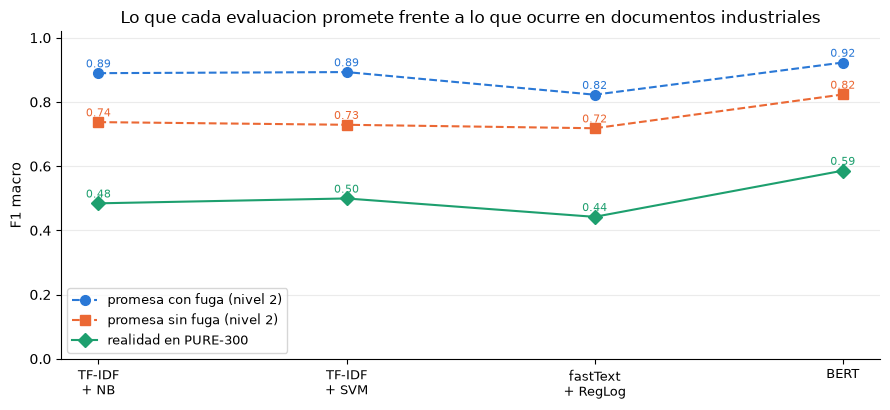

In [8]:
nombres_cortos = {"TF-IDF + MNB": "TF-IDF\n+ NB",
                  "TF-IDF + LinearSVC": "TF-IDF\n+ SVM",
                  "fastText + LogReg": "fastText\n+ RegLog",
                  "BERT (NoRBERT)": "BERT"}
modelos_aqui = [m for m in MODELOS if m in careo.modelo.values]
x = np.arange(len(modelos_aqui))
fig, eje = plt.subplots(figsize=(9, 4.2))
series = [("union con fuga", "promesa con fuga (nivel 2)", "#2a78d6", "o--"),
          ("union sin fuga (LOGO)", "promesa sin fuga (nivel 2)", "#eb6834", "s--"),
          ("realidad en PURE-300", "realidad en PURE-300", "#1d9f6e", "D-")]
for col, etiqueta, color, estilo in series:
    vals = [careo[careo.modelo == m][col].iloc[0] for m in modelos_aqui]
    eje.plot(x, vals, estilo, color=color, label=etiqueta, ms=7)
    for xi, v in enumerate(vals):
        eje.annotate(f"{v:.2f}", (xi, v + 0.018), ha="center", fontsize=8,
                     color=color)
eje.set_xticks(x, [nombres_cortos[m] for m in modelos_aqui], fontsize=9)
eje.set_ylabel("F1 macro")
eje.set_ylim(0, 1.02)
eje.set_title("Lo que cada evaluacion promete frente a lo que ocurre "
              "en documentos industriales")
eje.legend(fontsize=9, loc="lower left")
eje.spines[["top", "right"]].set_visible(False)
eje.yaxis.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel3_careo.pdf"))
plt.show()

## 6. Matrices de confusión y desempeño por documento

Sobre los 265 confirmados, con el entrenamiento de la unión. Como los documentos tienen distribuciones de clase muy distintas, se grafica la exactitud.

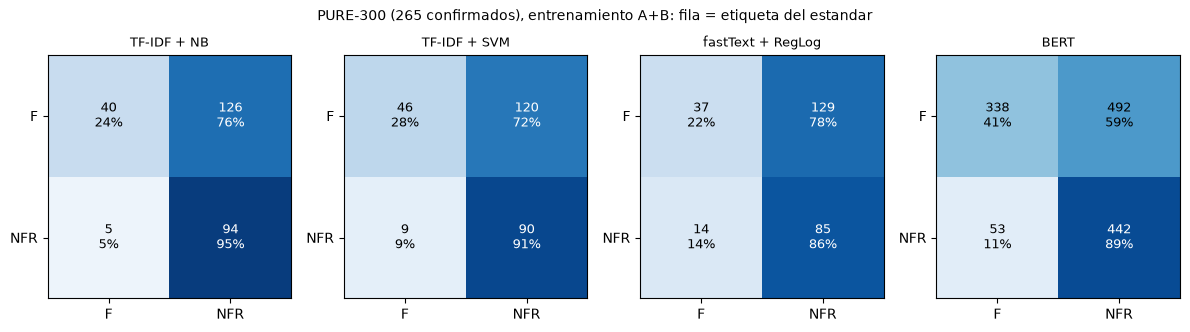

In [9]:
def pred_gold(nombre, cond="union"):
    if nombre == "BERT (NoRBERT)":
        if cond not in bert:
            return None
        d = bert[cond]
    else:
        d = predicciones[cond]
        d = d[d.modelo == nombre]
    return sobre_gold(d, True)

cols = [m for m in MODELOS if pred_gold(m) is not None]
fig, ejes = plt.subplots(1, len(cols), figsize=(3.0 * len(cols), 3.2))
for eje, nombre in zip(np.atleast_1d(ejes), cols):
    d = pred_gold(nombre)
    M = confusion_matrix(d.etiqueta_gold, d.prediccion, labels=CLASES)
    pct = M / M.sum(axis=1, keepdims=True)
    eje.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for r in range(2):
        for c in range(2):
            color = "white" if pct[r, c] > 0.6 else "black"
            eje.text(c, r, f"{M[r, c]}\n{pct[r, c]:.0%}", ha="center",
                     va="center", color=color, fontsize=9)
    eje.set_xticks([0, 1], CLASES)
    eje.set_yticks([0, 1], CLASES)
    eje.set_title(nombres_cortos[nombre].replace("\n", " "), fontsize=9)
fig.suptitle("PURE-300 (265 confirmados), entrenamiento A+B: "
             "fila = etiqueta del estandar", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel3_confusion.pdf"))
plt.show()

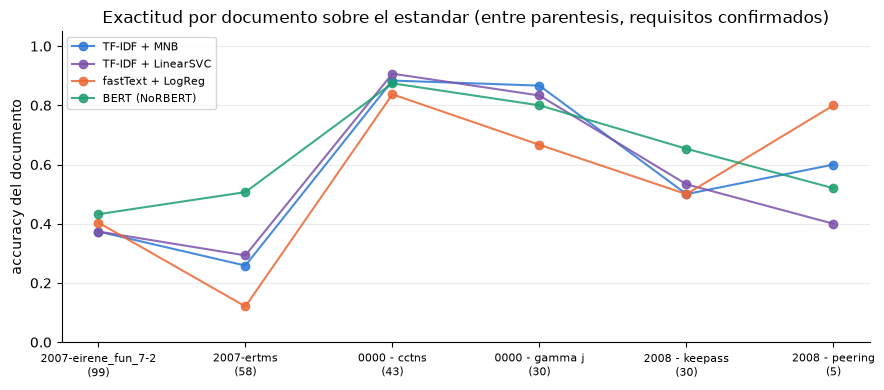

In [10]:
base = pred_gold(MODELOS_CLASICOS[0])
tam = base.groupby("documento").size()
orden_d = tam.sort_values(ascending=False).index.tolist()
colores = {"TF-IDF + MNB": "#2a78d6", "TF-IDF + LinearSVC": "#7b52ab",
           "fastText + LogReg": "#eb6834", "BERT (NoRBERT)": "#1d9f6e"}
fig, eje = plt.subplots(figsize=(9, 4.0))
for nombre in MODELOS:
    d = pred_gold(nombre)
    if d is None:
        continue
    acc = d.assign(ok=(d.etiqueta_gold == d.prediccion)).groupby("documento").ok.mean()
    eje.plot(range(len(orden_d)), acc.loc[orden_d].values, "o-", ms=6,
             label=nombre, color=colores[nombre], alpha=0.85)
eje.set_xticks(range(len(orden_d)), [f"{d}\n({tam[d]})" for d in orden_d],
               fontsize=8)
eje.set_ylabel("accuracy del documento")
eje.set_ylim(0, 1.05)
eje.set_title("Exactitud por documento sobre el estandar "
              "(entre parentesis, requisitos confirmados)")
eje.yaxis.grid(True, alpha=0.25)
eje.spines[["top", "right"]].set_visible(False)
eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(DIR_FIGURAS, "nivel3_por_documento.pdf"))
plt.show()

## 7. Salidas

En `datasets/nivel3/`: predicciones de las tres condiciones (clásicos y BERT), `nivel3_metricas.csv` con las dos poblaciones y las figuras.